# Shaken, Still Standing (Romania, Hard)

Verdict for every record in `sealed.csv`: deep Vrancea event or not. 48 spectral channels, 7500 labelled records, 5000 sealed.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import solution as sol
sns.set_theme(style="whitegrid", context="notebook")

train, sealed = sol.load()
CH = sol.CH
X, y = train[CH].to_numpy(), train.vrancea.to_numpy()
Xs = sealed[CH].to_numpy()
print(train.shape, sealed.shape)
print(train.vrancea.value_counts().to_dict())

(7500, 50) (5000, 49)
{0: 3786, 1: 3714}


## What the evaluator wants

The evaluator decodes a Reed-Solomon codeword built from our 0/1 answers (Gao decoder). It recovers the hidden polynomial only when at least `(n + k) / 2` answers are right. `n` and `k` are plain parameters in the vault.

In [2]:
z = np.load(sol.DATA / "vault.npz")
n, k = int(z["n"]), int(z["k"])
need = int(np.ceil((n + k) / 2))
print(f"n={n}  k={k}  need >= {need} correct  ->  accuracy >= {need / n:.4f}  (at most {n - need} errors)")

n=5000  k=4252  need >= 4626 correct  ->  accuracy >= 0.9252  (at most 374 errors)


So the target is plain accuracy of at least 92.5 % on the sealed set. The baseline (one model at a time) is far from it:

In [3]:
for name, m in [("logistic", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
                ("svm rbf", make_pipeline(StandardScaler(), SVC(C=3.0)))]:
    print(f"{name:10s} {cross_val_score(m, X, y, cv=sol.CV).mean():.4f}")

logistic   0.6008


svm rbf    0.6755


## EDA

### Channels: two kinds

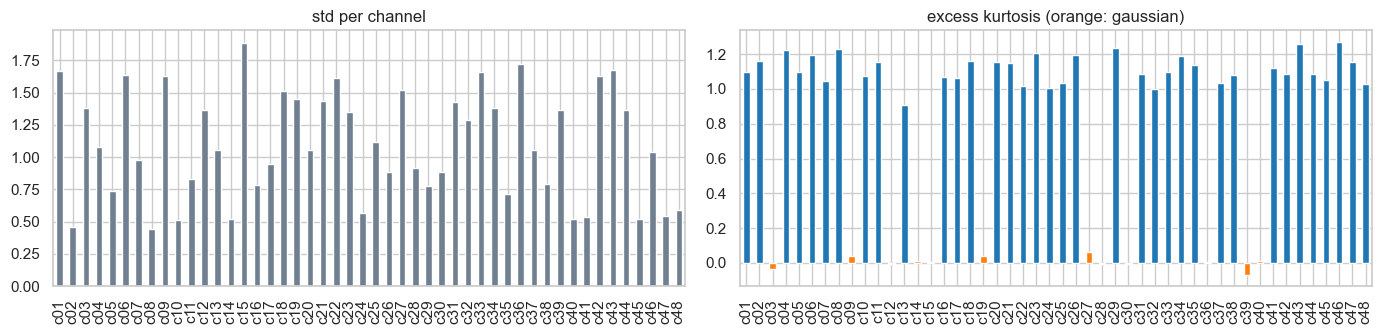

12 gaussian channels: ['c03', 'c09', 'c12', 'c14', 'c15', 'c19', 'c27', 'c28', 'c30', 'c36', 'c39', 'c40']


In [4]:
desc = pd.DataFrame({"mean": X.mean(0), "std": X.std(0), "kurt": stats.kurtosis(np.vstack([X, Xs])),
                     "skew": stats.skew(X)}, index=CH)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
desc["std"].plot.bar(ax=ax[0], color="slategray"); ax[0].set_title("std per channel")
colors = np.where(np.abs(desc["kurt"]) < 0.4, "tab:orange", "tab:blue")
desc["kurt"].plot.bar(ax=ax[1], color=colors); ax[1].set_title("excess kurtosis (orange: gaussian)")
plt.tight_layout(); plt.show()
gauss = desc.index[np.abs(desc["kurt"]) < 0.4].tolist()
print(len(gauss), "gaussian channels:", gauss)

12 channels are plain Gaussian, the other 36 have excess kurtosis near 0.9, which looks like a scale mixture. Linear correlations are flat:

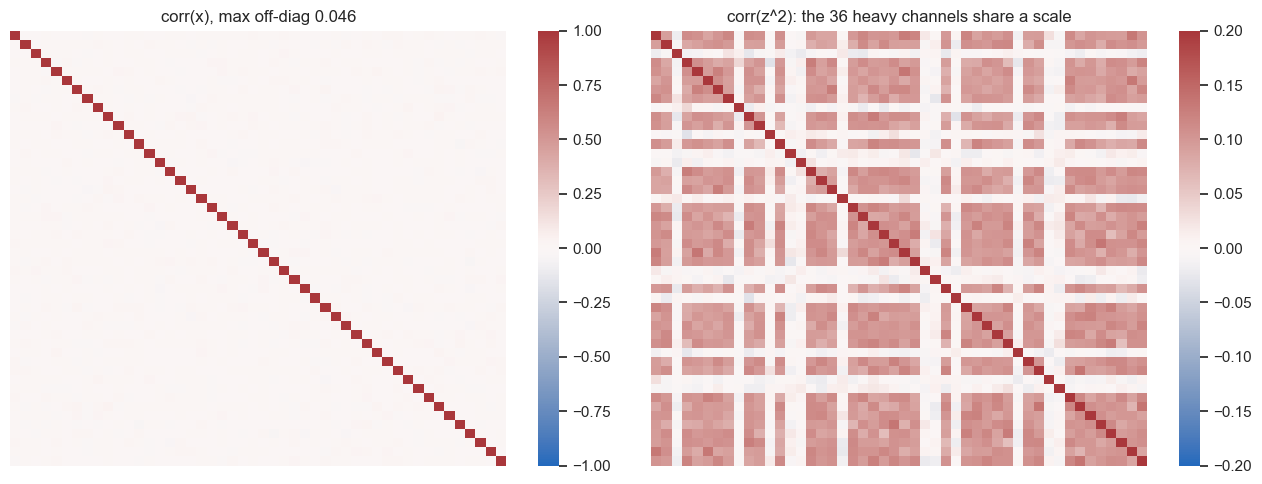

In [5]:
cor = np.corrcoef(X.T)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cor, ax=ax[0], cmap="vlag", vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
ax[0].set_title(f"corr(x), max off-diag {np.abs(cor - np.eye(48)).max():.3f}")
Z = (X - X.mean(0)) / X.std(0)
sns.heatmap(np.corrcoef((Z ** 2).T), ax=ax[1], cmap="vlag", vmin=-0.2, vmax=0.2, xticklabels=False, yticklabels=False)
ax[1].set_title("corr(z^2): the 36 heavy channels share a scale")
plt.tight_layout(); plt.show()

### A shared loudness factor

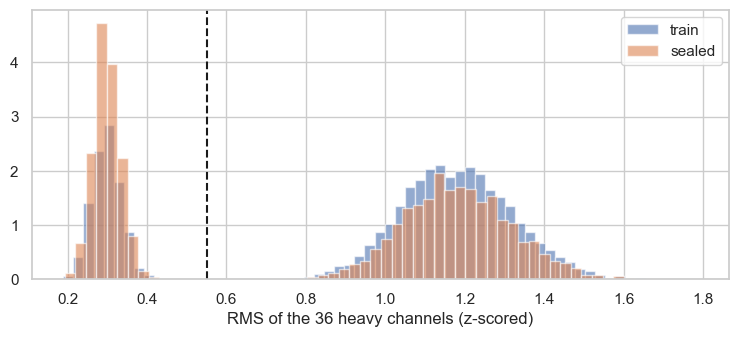

quiet share  train 0.253  sealed 0.400
label rate quiet / loud: 0.496 0.495
std ratio quiet/loud on heavy channels: 0.251


In [6]:
router = sol.Router().fit(np.vstack([X, Xs]))
lt, ls = router.loudness(X), router.loudness(Xs)
plt.figure(figsize=(9, 3.5))
plt.hist(lt, bins=60, alpha=.6, density=True, label="train"); plt.hist(ls, bins=60, alpha=.6, density=True, label="sealed")
plt.axvline(router.quiet_cut, c="k", ls="--"); plt.xlabel("RMS of the 36 heavy channels (z-scored)"); plt.legend(); plt.show()
qt, qs = lt < router.quiet_cut, ls < router.quiet_cut
print(f"quiet share  train {qt.mean():.3f}  sealed {qs.mean():.3f}")
print("label rate quiet / loud:", y[qt].mean().round(3), y[~qt].mean().round(3))
print("std ratio quiet/loud on heavy channels:", (X[qt][:, router.heavy].std(0) / X[~qt][:, router.heavy].std(0)).mean().round(3))

A quarter of the training records are *quiet*: the 36 heavy channels are shrunk to 1/4 around their means. The sealed set has 40 % quiet records, so there is a covariate shift.

### Which channels matter in each regime

In [7]:
G, Hh = router.gauss, router.heavy
rows = []
for name, m in [("quiet", qt), ("loud", ~qt)]:
    for cols, cn in [(G, "gaussian 12"), (Hh, "heavy 36"), (np.arange(48), "all 48")]:
        for mn, mod in [("svm", make_pipeline(StandardScaler(), SVC(C=3))),
                        ("grad_boost", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05))]:
            rows.append((name, cn, mn, cross_val_score(mod, X[m][:, cols], y[m], cv=sol.CV, n_jobs=5).mean()))
pd.DataFrame(rows, columns=["regime", "channels", "model", "cv_acc"]).pivot_table(
    index=["regime", "channels"], columns="model", values="cv_acc").round(3)

model               grad_boost    svm
regime channels                      
loud   all 48            0.909  0.647
       gaussian 12       0.522  0.529
       heavy 36          0.878  0.629
quiet  all 48            0.821  0.757
       gaussian 12       0.838  0.915
       heavy 36          0.498  0.514

Quiet records: the label lives only in the 12 Gaussian channels. Loud records: it lives mostly in the heavy channels and trees do much better than an RBF SVM.

### Quiet regime: distance from a centre

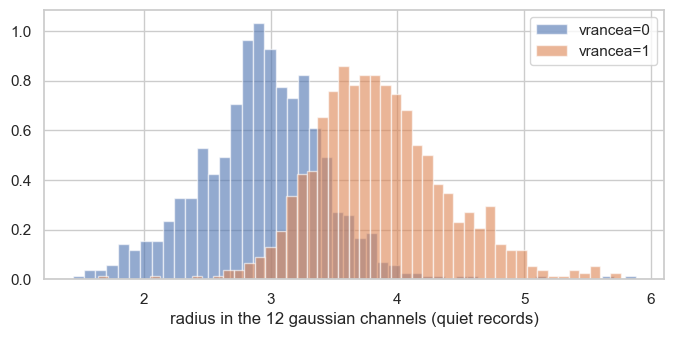

corr(radius, label) = 0.677


In [8]:
Gq = X[qt][:, G]; Zq = (Gq - Gq.mean(0)) / Gq.std(0)
r = np.sqrt((Zq ** 2).sum(1))
plt.figure(figsize=(8, 3.5))
for c in [0, 1]:
    plt.hist(r[y[qt] == c], bins=50, alpha=.6, density=True, label=f"vrancea={c}")
plt.xlabel("radius in the 12 gaussian channels (quiet records)"); plt.legend(); plt.show()
print("corr(radius, label) =", np.corrcoef(r, y[qt])[0, 1].round(3))

Vrancea records sit further out. The boundary is a tilted ellipsoid rather than a sphere (a full quadratic beats squares-only), so an RBF SVM and a quadratic logistic regression are the natural tools.

### Loud regime: a three-channel parity behind a gate

In [9]:
Xl, yl = X[~qt], y[~qt]
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50).fit(Xl, yl)
print(export_text(tree, feature_names=CH))

|--- c35 <= -0.18
|   |--- c43 <= -0.61
|   |   |--- c38 <= 0.73
|   |   |   |--- class: 1
|   |   |--- c38 >  0.73
|   |   |   |--- class: 0
|   |--- c43 >  -0.61
|   |   |--- c38 <= 0.73
|   |   |   |--- class: 0
|   |   |--- c38 >  0.73
|   |   |   |--- class: 1
|--- c35 >  -0.18
|   |--- c43 <= -0.61
|   |   |--- c38 <= 0.72
|   |   |   |--- class: 0
|   |   |--- c38 >  0.72
|   |   |   |--- class: 1
|   |--- c43 >  -0.61
|   |   |--- c38 <= 0.71
|   |   |   |--- class: 1
|   |   |--- c38 >  0.71
|   |   |   |--- class: 0



Every leaf flips with each split: the label is an XOR of three thresholds on c35, c43, c38. Sign-product pairs had already pointed at c35 x c43, and c13 kept showing up in pairwise interactions. Parity accuracy along c13:

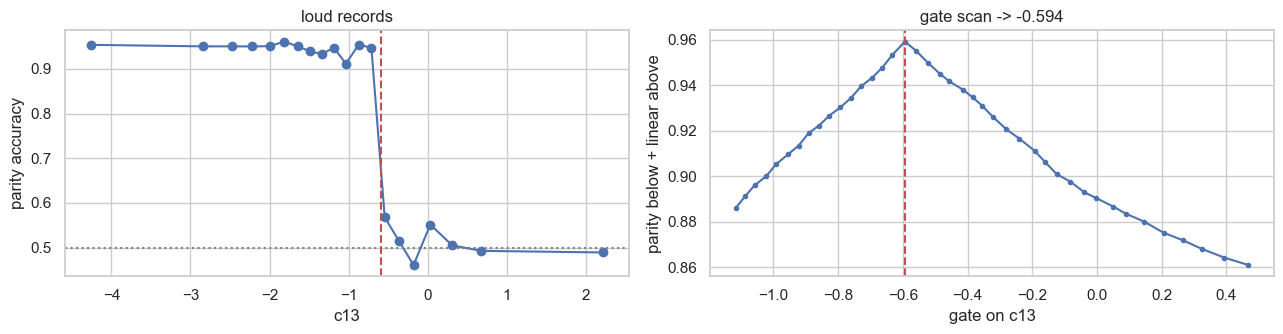

In [10]:
par = 1 - ((Xl[:, CH.index("c35")] > -0.18).astype(int) + (Xl[:, CH.index("c43")] > -0.61)
           + (Xl[:, CH.index("c38")] > 0.72)) % 2
c13 = Xl[:, CH.index("c13")]
edges = np.quantile(c13, np.linspace(0, 1, 21))
mid = (edges[:-1] + edges[1:]) / 2
acc = [(par[(c13 >= a) & (c13 <= b)] == yl[(c13 >= a) & (c13 <= b)]).mean() for a, b in zip(edges[:-1], edges[1:])]
gate = router.find_gate(X, y)
g, sc = router.gate_scan
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(mid, acc, "o-"); ax[0].axhline(.5, c="gray", ls=":"); ax[0].axvline(gate, c="r", ls="--")
ax[0].set_xlabel("c13"); ax[0].set_ylabel("parity accuracy"); ax[0].set_title("loud records")
ax[1].plot(g, sc, ".-"); ax[1].axvline(gate, c="r", ls="--"); ax[1].set_xlabel("gate on c13")
ax[1].set_ylabel("parity below + linear above"); ax[1].set_title(f"gate scan -> {gate:.3f}")
plt.tight_layout(); plt.show()

Below the gate the parity explains ~95 % with crude thresholds; above it the parity is a coin flip and a plain linear model takes over:

linear model above the gate: 0.9275
linear model below the gate: 0.5417


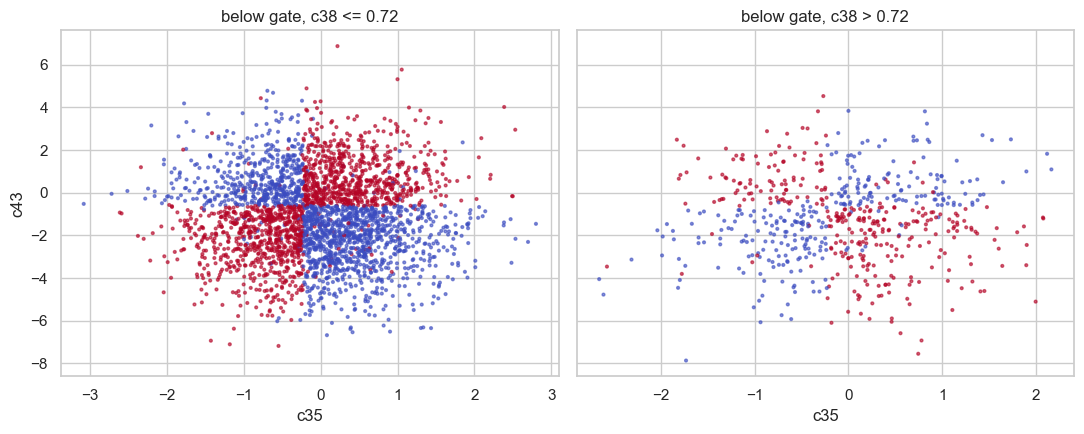

In [11]:
hi = c13 > gate
print("linear model above the gate:",
      cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000)), Xl[hi], yl[hi], cv=sol.CV).mean().round(4))
print("linear model below the gate:",
      cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000)), Xl[~hi], yl[~hi], cv=sol.CV).mean().round(4))
lo = ~hi
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for i, side in enumerate([Xl[lo][:, CH.index("c38")] <= 0.72, Xl[lo][:, CH.index("c38")] > 0.72]):
    d = Xl[lo][side]
    ax[i].scatter(d[:, CH.index("c35")], d[:, CH.index("c43")], c=yl[lo][side], cmap="coolwarm", s=4, alpha=.6)
    ax[i].set_title(f"below gate, c38 {'<=' if i == 0 else '>'} 0.72"); ax[i].set_xlabel("c35")
ax[0].set_ylabel("c43"); plt.tight_layout(); plt.show()

### Feature engineering

- `loudness`: RMS of the 36 heavy channels, splits quiet vs loud.
- `c13` gate, found by a scan on the training data.
- quiet segment: only the 12 Gaussian channels (quadratic terms inside the quadratic logistic model).
- parity segment: only c35, c43, c38.
- linear segment: all 48 channels.

### Segment mix, train vs sealed

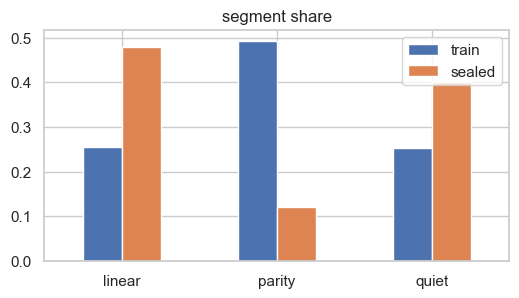

,train,sealed
linear,0.254,0.48
parity,0.493,0.12
quiet,0.253,0.40


In [12]:
seg, seg_n = router.segment(X), router.segment(Xs)
mix = pd.DataFrame({"train": pd.Series(seg).value_counts(normalize=True),
                    "sealed": pd.Series(seg_n).value_counts(normalize=True)}).round(3)
mix.plot.bar(figsize=(6, 3), rot=0); plt.title("segment share"); plt.show(); mix

The sealed set is mostly quiet and linear records, the two hardest segments. Training accuracy alone would flatter us; the expected sealed accuracy below reweights segment scores by the sealed mix.

## Models

Generic models on all 48 channels, their soft vote and a stacking model, then the routed ensemble: each segment gets its own candidates, the best ones are averaged (soft vote) and the router sends each record to its segment.

In [13]:
res = sol.main(call_eval=True)

gate c13 > -0.594
        train  sealed
linear  0.254    0.48
parity  0.493    0.12
quiet   0.253    0.40



generic models, 5-fold CV accuracy (all 48 channels):
  logistic        0.6008
  svm_rbf         0.6772
  knn             0.5176
  random_forest   0.7673
  grad_boost      0.8569
  mlp             0.6863
  soft_vote       0.7699
  stacking        0.8612



per-segment CV accuracy:
  quiet: svm_rbf=0.9326, quad_logistic=0.9279, mlp=0.9058, knn=0.5826, grad_boost=0.8379, vote=0.9374, n=1900
  parity: grad_boost=0.9705, random_forest=0.9724, svm_rbf=0.9215, knn=0.9042, logistic=0.5595, vote=0.9727, n=3696
  linear: logistic=0.9275, svm_rbf=0.9286, mlp=0.9238, knn=0.7731, grad_boost=0.8109, vote=0.9270, n=1904

routed ensemble CV accuracy (train mix): 0.9521
expected accuracy on the sealed mix:     0.9366


wrote predictions.csv [2544, 2456]



evaluator: SIGMOID_CONVOLUTION


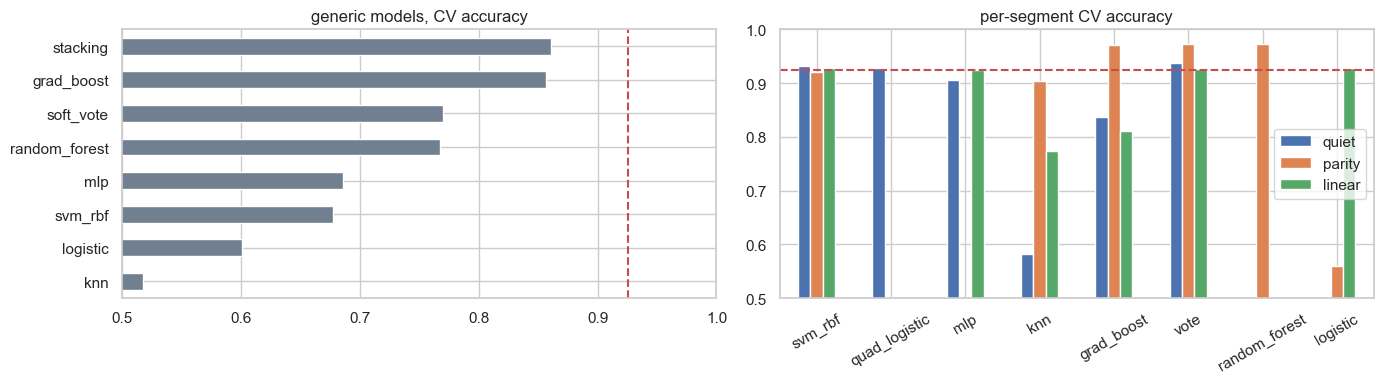

vote members: {'quiet': ['svm_rbf', 'quad_logistic'], 'parity': ['grad_boost', 'random_forest'], 'linear': ['logistic', 'svm_rbf', 'mlp']}
routed CV 0.9521 | expected on sealed mix 0.9366 | needed 0.9252


In [14]:
gen = pd.Series(res["generic"]).sort_values()
exp = pd.DataFrame(res["experts"]).T
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
gen.plot.barh(ax=ax[0], color="slategray"); ax[0].axvline(0.9252, c="r", ls="--"); ax[0].set_xlim(.5, 1)
ax[0].set_title("generic models, CV accuracy")
e = exp.drop(columns="n_train").T
e.plot.bar(ax=ax[1], rot=30); ax[1].axhline(0.9252, c="r", ls="--"); ax[1].set_ylim(.5, 1)
ax[1].set_title("per-segment CV accuracy")
plt.tight_layout(); plt.show()
print("vote members:", sol.VOTE)
print(f"routed CV {res['routed_cv']:.4f} | expected on sealed mix {res['expected_sealed']:.4f} | needed 0.9252")

## Evaluator

In [15]:
print(res["evaluator"])

SIGMOID_CONVOLUTION


## Notes

- Generic models top out around 0.86 (gradient boosting). Stacking them does not fix the problem: they are fighting three different rules at once.
- Splitting by loudness and the c13 gate turns the task into three easy problems: a quadratic boundary, a 3-channel parity, a hyperplane.
- Combination: hard routing between segments, soft voting inside each segment (SVM + quadratic logistic; boosting + forest; logistic + SVM + MLP).
- The gate is picked on the full training set, so the routed CV is slightly optimistic; the shift towards quiet/linear records in the sealed set is the main risk.